In [22]:
library(lme4)
library(ggplot2)

In [23]:
df <- read.csv("../concatenated_data/results.csv")
df$lang <- as.factor(df$lang)
df$preceding_tone <- as.factor(df$preceding_tone)
df$participant <- as.factor(df$participant)

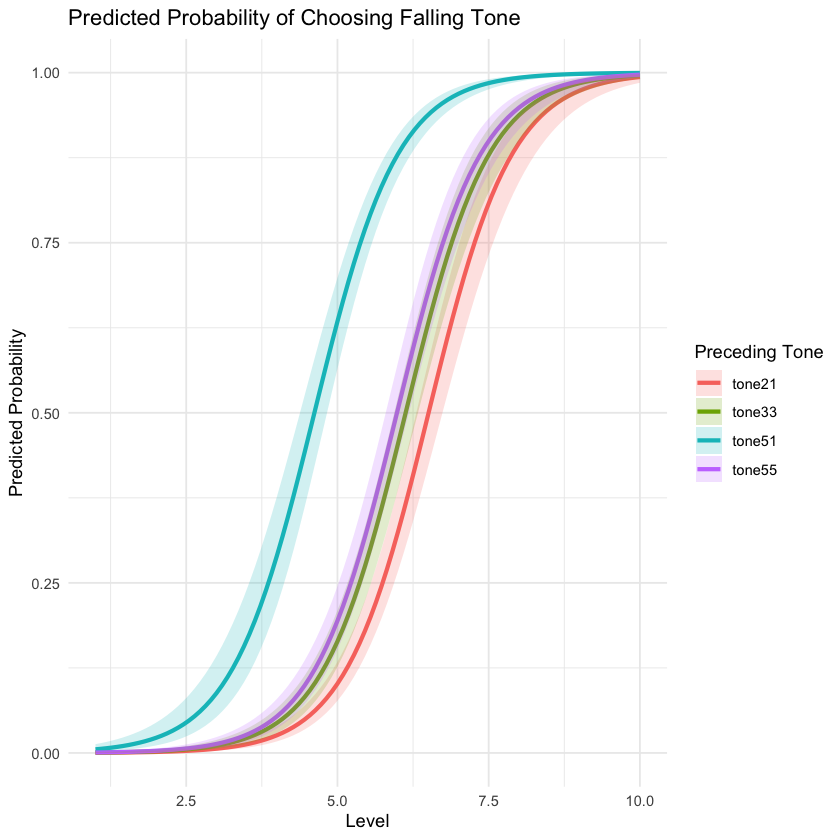

In [29]:
temp <- df
temp <- df[(df$lang=="min"),]

temp$preceding_tone <- droplevels(temp$preceding_tone)

model <- glmer(falling_tone_chosen ~ level + preceding_tone + (level|participant), family=binomial, data=temp)

newdata <- expand.grid(
  level = seq(min(temp$level), max(temp$level), length.out = 100),
  preceding_tone = levels(temp$preceding_tone)
)

betas <- fixef(model)
vcov_mat <- vcov(model)

X <- model.matrix(~ level + preceding_tone, newdata)

newdata$logit <- X %*% betas
newdata$se <- sqrt(diag(X %*% vcov_mat %*% t(X)))

newdata$logit_lower <- newdata$logit - 1.96 * newdata$se
newdata$logit_upper <- newdata$logit + 1.96 * newdata$se

newdata$predicted <- plogis(newdata$logit)
newdata$lower <- plogis(newdata$logit_lower)
newdata$upper <- plogis(newdata$logit_upper)

ggplot(newdata, aes(x = level, y = predicted, color = preceding_tone, fill = preceding_tone)) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, color = NA) +
  labs(
    title = "Predicted Probability of Choosing Falling Tone",
    x = "Level",
    y = "Predicted Probability",
    color = "Preceding Tone",
    fill = "Preceding Tone"
  ) +
  theme_minimal()

write.csv(newdata, "predicted_probs_min.csv", row.names = FALSE)

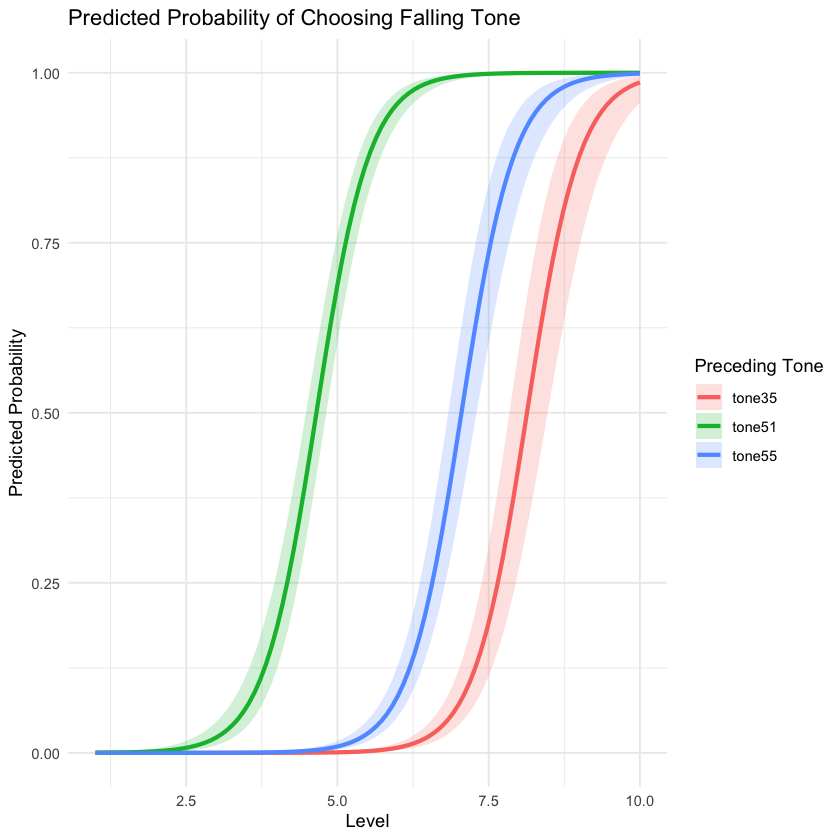

In [27]:
temp <- df
temp <- df[(df$lang=="man"),]
temp$preceding_tone <- droplevels(temp$preceding_tone)

model <- glmer(falling_tone_chosen ~ level+preceding_tone + (level|participant), family=binomial, data=temp)

newdata <- expand.grid(
  level = seq(min(temp$level), max(temp$level), length.out = 100),
  preceding_tone = levels(temp$preceding_tone)
)

betas <- fixef(model)
vcov_mat <- vcov(model)

X <- model.matrix(~ level + preceding_tone, newdata)

newdata$logit <- X %*% betas
newdata$se <- sqrt(diag(X %*% vcov_mat %*% t(X)))

newdata$logit_lower <- newdata$logit - 1.96 * newdata$se
newdata$logit_upper <- newdata$logit + 1.96 * newdata$se

newdata$predicted <- plogis(newdata$logit)
newdata$lower <- plogis(newdata$logit_lower)
newdata$upper <- plogis(newdata$logit_upper)

ggplot(newdata, aes(x = level, y = predicted, color = preceding_tone, fill = preceding_tone)) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, color = NA) +
  labs(
    title = "Predicted Probability of Choosing Falling Tone",
    x = "Level",
    y = "Predicted Probability",
    color = "Preceding Tone",
    fill = "Preceding Tone"
  ) +
  theme_minimal()

write.csv(newdata, "predicted_probs_man.csv", row.names = FALSE)

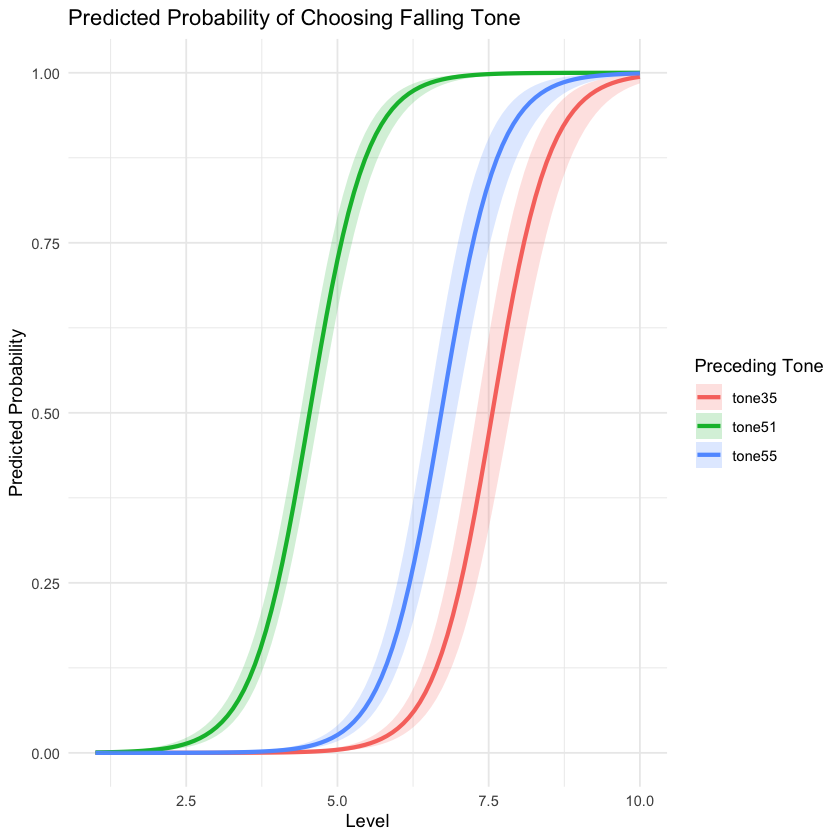

In [28]:
temp <- df
temp <- df[(df$lang=="man_bilingual"),]
temp$preceding_tone <- droplevels(temp$preceding_tone)

model <- glmer(falling_tone_chosen ~ level+preceding_tone + (level|participant), family=binomial, data=temp)

newdata <- expand.grid(
  level = seq(min(temp$level), max(temp$level), length.out = 100),
  preceding_tone = levels(temp$preceding_tone)
)

betas <- fixef(model)
vcov_mat <- vcov(model)

X <- model.matrix(~ level + preceding_tone, newdata)

newdata$logit <- X %*% betas
newdata$se <- sqrt(diag(X %*% vcov_mat %*% t(X)))

newdata$logit_lower <- newdata$logit - 1.96 * newdata$se
newdata$logit_upper <- newdata$logit + 1.96 * newdata$se

newdata$predicted <- plogis(newdata$logit)
newdata$lower <- plogis(newdata$logit_lower)
newdata$upper <- plogis(newdata$logit_upper)

ggplot(newdata, aes(x = level, y = predicted, color = preceding_tone, fill = preceding_tone)) +
  geom_line(size = 1.2) +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, color = NA) +
  labs(
    title = "Predicted Probability of Choosing Falling Tone",
    x = "Level",
    y = "Predicted Probability",
    color = "Preceding Tone",
    fill = "Preceding Tone"
  ) +
  theme_minimal()

write.csv(newdata, "predicted_probs_man_bilingual.csv", row.names = FALSE)